# Introduction

Hello, and welcome to the Maji Ndogo project!

Maji Ndogo is a fictional African country facing a range of interconnected challenges, including unequal access to clean water, aging infrastructure, and systemic corruption. While previous initiatives have focused on understanding and addressing these issues, our attention now turns to another critical sector: agriculture.

Our goal is to support the automation of farming across Maji Ndogo's diverse and often challenging agricultural landscapes. However, before we can determine *how* to automate farming, we first need to understand *where* different crops can be grown most successfully. Effective agricultural planning requires more than technology, it depends on making informed, data-driven decisions based on environmental conditions such as rainfall, soil fertility, climate, elevation, and geography.

The analysis we perform will lay the foundation for the entire automation project. By examining these variables, we can identify the most suitable locations for different crops, helping to maximize yields while making efficient use of available resources. Think of it as solving a complex puzzle, where every piece of data contributes to a clearer picture of the country's agricultural potential.

To begin, we'll import data from an SQLite database containing information spread across multiple tables. Since data analysis in Python is typically performed using DataFrames, we'll first need to combine these tables using SQL before transforming the data into a format suitable for analysis. As with most real-world datasets, we should expect inconsistencies, missing values, and other quality issues that will require cleaning and preparation before meaningful analysis can begin.

Once our data is ready, we'll explore it to uncover trends, relationships, and patterns that can guide agricultural decision-making. Together, we'll use these insights to recommend the most suitable crops for different regions, helping to build a smarter and more sustainable farming system for Maji Ndogo.

Let's get started and discover what the data has to tell us.

**Sanaa**

# Data dictionary

**1. Geographic features**

- **Field_ID:** A unique identifier for each field (BigInt).
 
- **Elevation:** The elevation of the field above sea level in metres (Float).

- **Latitude:** Geographical latitude of the field in degrees (Float).

- **Longitude:** Geographical longitude of the field in degrees (Float).

- **Location:** Province the field is in (Text).

- **Slope:** The slope of the land in the field (Float).

**2. Weather features**

- **Field_ID:** Corresponding field identifier (BigInt).

- **Rainfall:** Amount of rainfall in the area in mm (Float).

- **Min_temperature_C:** Average minimum temperature recorded in Celsius (Float).

- **Max_temperature_C:** Average maximum temperature recorded in Celsius (Float).

- **Ave_temps:** Average temperature in Celcius (Float).

**3. Soil and crop features**

- **Field_ID:** Corresponding field identifier (BigInt).

- **Soil_fertility:** A measure of soil fertility where 0 is infertile soil, and 1 is very fertile soil (Float).

- **Soil_type:** Type of soil present in the field (Text).

- **pH:** pH level of the soil, which is a measure of how acidic/basic the soil is (Float).

**4. Farm management features**

- **Field_ID:** Corresponding field identifier (BigInt).

- **Pollution_level:** Level of pollution in the area where 0 is unpolluted and 1 is very polluted (Float).

- **Plot_size:** Size of the plot in the field (Ha) (Float).

- **Chosen_crop:** Type of crop chosen for cultivation (Text).

- **Annual_yield:** Annual yield from the field (Float). This is the total output of the field. The field size and type of crop will affect the Annual Yield

- **Standard_yield:** Standardised yield expected from the field, normalised per crop (Float). This is independent of field size, or crop type. Multiplying this number by the field size, and average crop yield will give the Annual_Yield.

**Average yield (tons/Ha) per crop type:**
- **Coffee:** 1.5 

- **Wheat:** 3

- **Rice:** 4.5

- **Maize:** 5.5

- **Tea:** 1.2

- **Potato:** 20

- **Banana:** 30

- **Cassava:** 13



Alright, let's walk through the process of importing our SQL data from multiple tables into a single DataFrame. This is a crucial step as it sets the foundation for all our subsequent analyses.

We're dealing with an SQLite database, `Maji_Ndogo_farm_survey.db`, which contains multiple tables. We'll need to join these tables on a common key to create a comprehensive dataset for our analysis. The common key in our case is `Field_ID`.

Here’s how we can do it:

In [1]:
import pandas as pd # importing the Pandas package with an alias, pd
from sqlalchemy import create_engine, text # Importing the SQL interface. If this fails, run !pip install sqlalchemy in another cell.

# Create an engine for the database
engine = create_engine('sqlite:///Maji_Ndogo_farm_survey_small.db') #Make sure to have the .db file in the same directory as this notebook, and the file name matches.

Next up, we test if the connection works by printing out all of the table names in the database.

In [2]:
with engine.connect() as connection:
    result = connection.execute(text("SELECT name FROM sqlite_master WHERE type='table';"))
    for row in result:
        print(row)

('geographic_features',)
('weather_features',)
('soil_and_crop_features',)
('farm_management_features',)


**Expected output:**

`('geographic_features',)`

`('weather_features',)`

`('soil_and_crop_features',)`

`('farm_management_features',)`

At this point, we have two choices:

1. Either we import each table into a DataFrame, for example, `df_geographic`, then merge them together.

2. Use one SQL query and read it into a single DataFrame.

While both are equally viable, let's try to use a single SQL query to keep things simple.

Next, we'll write an SQL query to join our tables. Combine all of the tables into a single query, using `Field_ID`.

In [4]:
sql_query = """
SELECT *
FROM geographic_features gf
JOIN weather_features wf
    ON gf.Field_ID = wf.Field_ID
JOIN soil_and_crop_features scf
    ON gf.Field_ID = scf.Field_ID
JOIN farm_management_features fmf
    ON gf.Field_ID = fmf.Field_ID;
"""

With our engine and query ready, we'll use `Pandas` to execute the query. The `pd.read_sql_query` function fetches the data and loads it into a DataFrame – essentially transferring our data from the database into a familiar `Pandas` structure. If you use one query, you will import it all into `MD_agric_df`. 

In [5]:
# Create a connection object
with engine.connect() as connection:
    
    # Use Pandas to execute the query and store the result in a DataFrame
    MD_agric_df = pd.read_sql_query(text(sql_query), connection)

Check the DataFrame to see if it loaded correctly.

In [6]:
MD_agric_df

,Field_ID,Elevation,Latitude,Longitude,Location,Slope,Field_ID,Rainfall,Min_temperature_C,Max_temperature_C,...,Field_ID,Soil_fertility,Soil_type,pH,Field_ID,Pollution_level,Plot_size,Crop_type,Annual_yield,Standard_yield
0,40734,786.05580,-7.389911,-7.556202,Rural_Akatsi,14.795113,40734,1125.2,-3.1,33.1,...,40734,0.62,Sandy,6.169393,40734,8.526684e-02,1.3,0.751354,cassava,0.577964
1,30629,674.33410,-7.736849,-1.051539,Rural_Sokoto,11.374611,30629,1450.7,-3.9,30.6,...,30629,0.64,Volcanic,5.676648,30629,3.996838e-01,2.2,1.069865,cassava,0.486302
2,39924,826.53390,-9.926616,0.115156,Rural_Sokoto,11.339692,39924,2208.9,-1.8,28.4,...,39924,0.69,Volcanic,5.331993,39924,3.580286e-01,3.4,2.208801,tea,0.649647
3,5754,574.94617,-2.420131,-6.592215,Rural_Kilimani,7.109855,5754,328.8,-5.8,32.2,...,5754,0.54,Loamy,5.328150,5754,2.866871e-01,2.4,1.277635,cassava,0.532348
4,14146,886.35300,-3.055434,-7.952609,Rural_Kilimani,55.007656,14146,785.2,-2.5,31.0,...,14146,0.72,Sandy,5.721234,14146,4.319027e-02,1.5,0.832614,wheat,0.555076
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5649,11472,681.36145,-7.358371,-6.254369,Rural_Akatsi,16.213196,11472,885.7,-4.3,33.4,...,11472,0.61,Sandy,5.741063,11472,3.286828e-01,1.1,0.609930,potato,0.554482
5650,19660,667.02120,-3.154559,-4.475046,Rural_Kilimani,2.397553,19660,501.1,-4.8,32.1,...,19660,0.54,Sandy,5.445833,19660,1.602583e-01,8.7,3.812289,maize,0.438194
5651,41296,670.77900,-14.472861,-6.110221,Rural_Hawassa,7.636470,41296,1586.6,-3.8,33.4,...,41296,0.64,Volcanic,5.385873,41296,8.221326e-09,2.1,1.681629,tea,0.800776
5652,33090,429.48840,-14.653089,-6.984116,Rural_Hawassa,13.944720,33090,1272.2,-6.2,34.6,...,33090,0.63,Silt,5.562508,33090,6.917245e-10,1.3,0.659874,cassava,0.507595


Note that there are a couple of `Field_ID` columns in our DataFrame that we need to remove since we're not interested in particular farms for now.

In [7]:
# Now, drop all columns named 'Field_ID'.
MD_agric_df.drop(columns = 'Field_ID', inplace = True)

# Data cleanup

I noticed some errors in the data. Here's what I picked up:

1. There are some swapped column names. 

2. Some of the crop types contain spelling errors.

3.  The `Elevation` column contains some negative values, which are not plausible, so change these to positive values.

In [10]:
MD_agric_df[['Crop_type', 'Annual_yield']] = MD_agric_df[['Annual_yield', 'Crop_type']]

MD_agric_df['Elevation'] = MD_agric_df['Elevation'].abs()

MD_agric_df['Crop_type'] = MD_agric_df['Crop_type'].str.strip()
MD_agric_df['Crop_type'] = MD_agric_df['Crop_type'].replace({
    'cassaval': 'cassava',
    'wheatn': 'wheat',
    'teaa': 'tea'
})

MD_agric_df['Crop_type'] = MD_agric_df['Crop_type'].str.lower()

## Final data checkup

In [11]:
len(MD_agric_df['Crop_type'].unique())

8

Expected output: `8`

In [12]:
MD_agric_df['Elevation'].min()

35.910797

Expected output: `35.910797`

In [13]:
MD_agric_df['Annual_yield'].dtype

dtype('float64')

Expected outcome: `dtype('float64')`

# Analysis

## Challenge 1: Uncovering crop preferences

Now that we have our data ready, let's delve into understanding where different crops are grown in Maji Ndogo. Our initial step is to focus on tea, a key crop in Maji Ndogo. We need to determine the optimal conditions for its growth. By analyzing data related to elevation, rainfall, and soil type specifically for tea plantations, we'll start to paint a picture of where our farming systems could thrive.

**Task:**
Create a function that includes only tea fields and returns a tuple with the mean `Rainfall` and the mean `Elevation`. The function should input the full DataFrame, a string value for the crop type to filter by, and output a tuple with rainfall and elevation.


In [14]:
def explore_crop_distribution(df, crop_type):
    # Filter only the selected crop
    filtered_df = df[df['Crop_type'] == crop_type]

    # Calculate means
    mean_rainfall = filtered_df['Rainfall'].mean()
    mean_elevation = filtered_df['Elevation'].mean()

    # Return as tuple
    return (mean_rainfall, mean_elevation)

Input:

In [15]:
explore_crop_distribution(MD_agric_df, "tea")

(1534.5079956188388, 775.208667535597)

Expected output: `(1534.5079956188388, 775.208667535597)`

In [16]:
explore_crop_distribution(MD_agric_df, "wheat")

(1010.2859910581222, 595.8384148002981)

Expected output: `(1010.2859910581222, 595.8384148002981)`

Repeat this for a couple of crops to get a feeling for where crops are planted in Majio Ndogo.

## Challenge 2: Finding fertile grounds


With insights into tea cultivation, let's broaden our horizons. Fertile soil is the bedrock of successful farming. By grouping our data by location and soil type, we'll pinpoint where the most fertile soils in Maji Ndogo are. These fertile zones could be prime candidates for diverse crop cultivation, maximising our yield.

We’ll group our data by soil type to see where the most fertile grounds are. This information will be vital for deciding where to deploy our farming technology.

**Task:** Create a function that groups the data by `Soil_type`, and returns the `Soil_fertility`.

In [17]:
def analyse_soil_fertility(df):
    return df.groupby('Soil_type')['Soil_fertility'].mean()

Input:

In [18]:
analyse_soil_fertility(MD_agric_df)

Soil_type
Loamy       0.585868
Peaty       0.604882
Rocky       0.582368
Sandy       0.595669
Silt        0.652654
Volcanic    0.648894
Name: Soil_fertility, dtype: float64

Expected output:
```python Soil_Type
Loamy       0.585868
Peaty       0.604882
Rocky       0.582368
Sandy       0.595669
Silt        0.652654
Volcanic    0.648894
Name: Soil_Fertility, dtype: float64
```

Try digging into the data a bit more by aggregating various data to identify some more patterns. 

## Challenge 3: Climate and geography analysis

Now, let's delve into how climate and geography influence farming. By understanding the relationship between factors like elevation, temperature, and rainfall with crop yields, we can identify the most suitable areas for different crops. This analysis is key to ensuring our automated systems are deployed in locations that will maximise their effectiveness.

**Task:** Create a function that takes in a DataFrame and the column name, and groups the data by that column, and aggregates the data by the means of `Elevation`, `Min_temperature_C`, `Max_temperature_C`, and `Rainfall`, and outputs a DataFrame.

In [29]:
def climate_geography_influence(df,column):
    return (
        df.groupby(column)[
            ['Elevation', 'Min_temperature_C', 'Max_temperature_C', 'Rainfall']
        ]
        .mean()
    )

Input:

In [30]:
climate_geography_influence(MD_agric_df, 'Crop_type')

,Elevation,Min_temperature_C,Max_temperature_C,Rainfall
Crop_type,,,,
banana,487.973572,-5.354344,31.988152,1659.905687
cassava,682.903008,-3.992113,30.902381,1210.543006
coffee,647.047734,-4.028007,30.855189,1527.265074
maize,680.596982,-4.497995,30.576692,681.010276
potato,696.313917,-4.375334,30.300608,660.289064
rice,352.858053,-6.610566,32.727170,1632.382642
tea,775.208668,-2.862651,29.950383,1534.507996
wheat,595.838415,-4.968107,30.973845,1010.285991


Expected output:

```sql
Crop_type 	Elevation	Min_temperature_C	Max_temperature_C	Rainfall			
banana		487.973572	-5.354344		31.988152	    1659.905687
cassava		682.903008	-3.992113		30.902381	    1210.543006
coffee		647.047734	-4.028007		30.855189	    1527.265074
maize		680.596982	-4.497995		30.576692	    681.010276
potato		696.313917	-4.375334		30.300608	    660.289064
rice		352.858053	-6.610566		32.727170	    1632.382642
tea		775.208668	-2.862651		29.950383	    1534.507996
wheat		595.838415	-4.968107		30.973845	    1010.285991
```

## Challenge 4: Advanced sorting techniques

Quite often it is better to improve the things you're good at than improving the things you're bad at. So the question is, which crop is the top performer in Maji Ndogo, and under what conditions does it perform well? 

To answer this, we need to:
1. Filter all the fields with an above-average `Standard_yield`.
2. Then group by <?> crop type, using `count()`.
3. Sort the values to get the top crop type on top.
4. Retrieve the name of the top index. See the hint below on how to do this. 

**Task:** Create a function that takes a DataFrame as input, filters, groups and sorts, and outputs a string value of a crop type.

In [ ]:
grouped_df = MD_agric_df.groupby("Soil_type").mean(numeric_only = True).sort_values(by="Elevation",ascending=False)
print(grouped_df.index[0])
grouped_df

In [23]:
def find_ideal_fields(df):
    filtered_df = df[df['Standard_yield'] > df['Standard_yield'].mean()]
    
    grouped_df = filtered_df.groupby('Crop_type').size().sort_values(ascending=False)
    
    return grouped_df.index[0]

Input:

In [24]:
type(find_ideal_fields(MD_agric_df))

str

Expected output: `str`

# Challenge 5: Advanced filtering techniques

Now we know that <?> is our most successful crop, we can look at what makes it successful.

Create a function that takes a DataFrame as input, and the type of crop, and filters the DataFrame using the following conditions:
1. Filter by crop type.

2. Select only rows that have above average `Standard_yield`.

3. Select only rows that have `Ave_temps` >= 12 but =< 15.

4. Have a `Pollution_level` lower than 0.0001.

In [25]:
def find_good_conditions(df, crop_type):
    return df[
        (df['Crop_type'] == crop_type) &
        (df['Standard_yield'] > df['Standard_yield'].mean()) &
        (df['Ave_temps'] >= 12) &
        (df['Ave_temps'] <= 15) &
        (df['Pollution_level'] < 0.0001)
    ]

Input:

In [26]:
find_good_conditions(MD_agric_df, "tea").shape

(14, 17)

Expected output: `(14, 17)`

# Extra Pandas "nuggets"

Here are two tiny 'nuggets' to upskill in Pandas.

## df.query()

`df.query()` was designed to filter data, but using SQL-like syntax. For example:

In [27]:
MD_agric_df.query('Standard_yield > 0.5 and Soil_type == "Loamy"')

,Elevation,Latitude,Longitude,Location,Slope,Rainfall,Min_temperature_C,Max_temperature_C,Ave_temps,Soil_fertility,Soil_type,pH,Pollution_level,Plot_size,Crop_type,Annual_yield,Standard_yield
3,574.94617,-2.420131,-6.592215,Rural_Kilimani,7.109855,328.8,-5.8,32.2,13.20,0.54,Loamy,5.328150,0.286687,2.4,cassava,1.277635,0.532348
19,610.99400,-6.948353,-2.966000,Rural_Hawassa,16.369598,902.8,-4.9,28.4,11.75,0.61,Loamy,4.698949,0.303487,1.5,wheat,0.791114,0.527409
22,504.42505,-2.379580,-7.601249,Rural_Kilimani,3.906222,335.3,-6.4,32.6,13.10,0.53,Loamy,5.429212,0.057291,7.1,wheat,4.256354,0.599486
26,525.38104,-2.465188,-5.186775,Rural_Kilimani,6.809244,298.6,-6.3,33.8,13.75,0.54,Loamy,6.453105,0.192563,4.8,potato,2.603143,0.542321
44,562.14720,-7.953123,-2.222739,Rural_Sokoto,24.619905,1200.3,-5.3,31.8,13.25,0.66,Loamy,4.649274,0.262477,1.4,tea,0.948407,0.677433
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5617,636.75790,-7.322326,-5.128215,Rural_Hawassa,17.667543,812.0,-4.8,30.6,12.90,0.61,Loamy,4.882120,0.193366,0.8,cassava,0.442964,0.553705
5621,509.44156,-6.614932,-1.641644,Rural_Sokoto,19.441830,958.9,-5.8,31.5,12.85,0.62,Loamy,5.485380,0.800948,1.7,cassava,0.943078,0.554751
5625,614.65955,-6.948353,-3.029065,Rural_Hawassa,2.801264,896.6,-4.9,28.5,11.80,0.57,Loamy,4.809189,0.288357,5.3,potato,3.053344,0.576103
5632,618.01624,-6.511301,-2.574099,Rural_Hawassa,19.183754,888.0,-4.9,26.9,11.00,0.62,Loamy,5.231630,0.499646,0.7,wheat,0.350604,0.500862


Isn't that much easier to read and understand than the one below?

In [ ]:
MD_agric_df[(MD_agric_df['Standard_yield'] > 0.5) & (MD_agric_df['Soil_type'] == 'Loamy')]

The nice thing is, we can use `in []`, `not in []` to filter with, and also pass in variables using `@variable_name`.

In [ ]:
soil_types = ['Loamy', 'Sandy', 'Silt']

MD_agric_df.query('Soil_type in @soil_types')

# Plotting data with Pandas

Sometimes we quickly want to see a basic visualisation of our data. we can use `df.plot(kind='bar')` to make a bar plot, `df.plot(kind='hist', bins = 10)` to see the distribution of a data column, or `df.plot(kind='scatter', x='Column_on_x', y='Column_on_y')` to understand the relationship between variables.

<Axes: xlabel='Crop_type'>

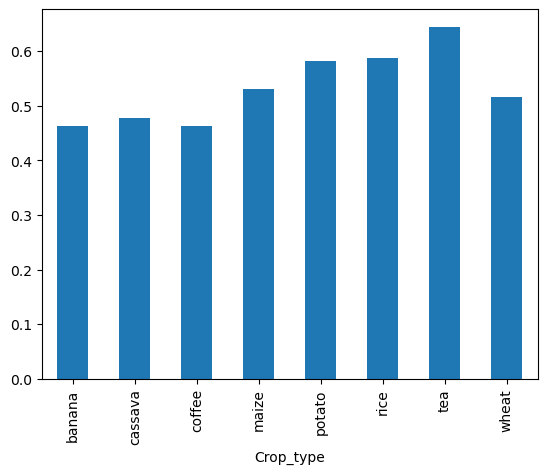

In [28]:
MD_agric_df.groupby('Crop_type')['Standard_yield'].mean().plot(kind='bar')

In [ ]:
MD_agric_df['Standard_yield'].plot(kind='hist', bins =20)

In [ ]:
MD_agric_df.plot(kind='scatter', x = "Pollution_level", y = "Standard_yield")

We can use these plots to get a quick feel for the data, but we can't really customise these much. For that we need some better tools. 

#  

<div align="center" style=" font-size: 80%; text-align: center; margin: 0 auto">
<img src="https://raw.githubusercontent.com/Explore-AI/Pictures/master/ExploreAI_logos/EAI_Blue_Dark.png"  style="width:200px";/>
</div>